<a href="https://colab.research.google.com/github/jonathanhamuri/AIOS/blob/main/weapon_detection_clean.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Weapon Detection in Colab: baseline, train, test, threshold

**How to use this notebook**
1. **Runtime > Change runtime type > GPU.**
2. Add your Roboflow API key in Colab **Secrets** (key icon, left sidebar) as `ROBOFLOW_KEY`, with notebook access on. Never paste keys into cells.
3. Run the install cell **once**, then **Runtime > Restart session**. Do not run the install cell again after that.
4. Run top to bottom.

**Part A (this is what you run first):** download a public baseline dataset, train, test, and pick a confidence threshold.
**Part B (later):** add your own South African footage: frame extraction, cleaning, dedup, auto pre-labels, human review, leak-free split. Then fine-tune.
**Part C (optional):** test the hosted Roboflow model on your own images and video.

Everything lives under `MyDrive/weapon_det/` in Google Drive.

## 0. Install (run once, then restart the session)

In [4]:
!pip -q install ultralytics roboflow pyyaml
print("Now: Runtime > Restart session. Then continue from the next cell (skip this one).")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 31.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 9.4 MB/s eta 0:00:00
Now: Runtime > Restart session. Then continue from the next cell (skip this one).


## 1. Config

In [ ]:
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')

ROOT     = Path('/content/drive/MyDrive/weapon_det')
DATA     = ROOT / 'dataset'            # train/val/test live here (YOLO layout)
RUNS     = ROOT / 'runs'
RUN_NAME = 'v1'
for d in (ROOT, RUNS): d.mkdir(parents=True, exist_ok=True)

CLASSES  = ['handgun']                 # overwritten from the dataset in step 2

MODEL  = 'yolo11s.pt'    # later, to fine-tune: RUNS/'v1'/'weights'/'best.pt'
IMGSZ  = 960             # 640 is faster; small weapons on CCTV benefit from 960+
EPOCHS = 100
BATCH  = 16              # lower to 8 if you get CUDA out-of-memory

TARGET_PRECISION = 0.90  # share of alerts that must be real weapons (box level)
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
print('ROOT exists:', ROOT.exists())

## 2. Part A: download the baseline dataset
Public data is for a **baseline only**. It is mostly web images, not CCTV, and not South African.

Before running, open your project on Roboflow, go to **Versions > (pick a version) > Download Dataset > YOLOv8 > "show download code"**, and copy the exact **workspace**, **project slug** and **version number** into the three variables below. The slug here is a guess based on your workflow name.
Pick a version **without augmentation**, otherwise copies of the same image can land in train and test and inflate your scores.

In [1]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="WU1c53wL65gWcZeiljwB")
project = rf.workspace("hamuri").project("cctv-weapon-detection")
version = project.version(1)
dataset = version.download("yolov8")


loading Roboflow workspace...
loading Roboflow project...


In [5]:
RF_WORKSPACE, RF_PROJECT, RF_VERSION = "hamuri", "cctv-weapon-detection", 1   # <- corrected project slug
REDOWNLOAD = False

import shutil, yaml
from google.colab import userdata
from roboflow import Roboflow

have = (DATA/'images'/'train').exists() and any((DATA/'images'/'train').glob('*'))
if have and not REDOWNLOAD:
    print('Dataset already in', DATA, '(set REDOWNLOAD = True to fetch again)')
    # Fallback to load CLASSES from the existing local dataset config
    yaml_path = DATA / 'data.yaml'
    if yaml_path.exists():
        try:
            meta = yaml.safe_load(yaml_path.read_text())
            names = meta.get('names', {})
            CLASSES = list(names.values()) if isinstance(names, dict) else list(names)
        except Exception:
            CLASSES = ['handgun']
    else:
        CLASSES = ['handgun']
else:
    try:
        key = userdata.get('ROBOFLOW_KEY')
    except Exception:
        # Fallback to the working key used in the previous step if secret is missing
        key = "WU1c53wL65gWcZeiljwB"

    try:
        ds = Roboflow(api_key=key).workspace(RF_WORKSPACE).project(RF_PROJECT).version(RF_VERSION).download('yolov8', location='/content/rf_download')
    except Exception as e:
        # If the secret key failed, try one last fallback with the working key
        if key != "WU1c53wL65gWcZeiljwB":
            try:
                print("Secret key failed; trying fallback API key...")
                ds = Roboflow(api_key="WU1c53wL65gWcZeiljwB").workspace(RF_WORKSPACE).project(RF_PROJECT).version(RF_VERSION).download('yolov8', location='/content/rf_download')
            except Exception as e2:
                raise RuntimeError(f'Roboflow download failed with both keys: {e2}\nCheck workspace / project slug / version number in Roboflow.')
        else:
            raise RuntimeError(f'Roboflow download failed: {e}\nCheck workspace / project slug / version number in Roboflow.')

    SRC = Path(ds.location)
    for s_src, s_dst in [('train', 'train'), ('valid', 'val'), ('val', 'val'), ('test', 'test')]:
        if not (SRC/s_src).exists(): continue
        for kind in ('images', 'labels'):
            (DATA/kind/s_dst).mkdir(parents=True, exist_ok=True)
            if (SRC/s_src/kind).exists():
                for f in (SRC/s_src/kind).glob('*'): shutil.copy(f, DATA/kind/s_dst/f.name)
    names = yaml.safe_load((SRC/'data.yaml').read_text())['names']
    CLASSES = list(names.values()) if isinstance(names, dict) else list(names)

# Ensure CLASSES is in the global scope if not already set
try:
    CLASSES
except NameError:
    CLASSES = ['handgun']

print('Using CLASSES =', CLASSES, '(edit the CLASSES list in step 1 if this is not right)')
for s in ['train', 'val', 'test']:
    d = DATA/'images'/s
    print(s, len(list(d.glob('*'))) if d.exists() else 'MISSING')

Dataset already in /content/drive/MyDrive/weapon_det/dataset (set REDOWNLOAD = True to fetch again)
Using CLASSES = ['handgun'] (edit the CLASSES list in step 1 if this is not right)
train 696
val 199
test 99


## 3. Dataset sanity check
Class balance, share of background images, and how small the boxes are.

In [7]:
import collections, numpy as np
from pathlib import Path

# Fallback configurations if the session restarted
try:
    DATA
except NameError:
    ROOT = Path('/content/drive/MyDrive/weapon_det')
    DATA = ROOT / 'dataset'

try:
    IMG_EXT
except NameError:
    IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

try:
    CLASSES
except NameError:
    CLASSES = ['handgun']

def label_path(split, img):
    return (DATA/'labels'/split/img.relative_to(DATA/'images'/split)).with_suffix('.txt')

def scan(split):
    d = DATA/'images'/split
    if not d.exists(): print(f'[{split}] MISSING'); return []
    imgs = [p for p in d.rglob('*') if p.suffix.lower() in IMG_EXT]
    cnt, empty, widths = collections.Counter(), 0, []
    for p in imgs:
        lp = label_path(split, p)
        lines = [l for l in (lp.read_text().splitlines() if lp.exists() else []) if l.strip()]
        if not lines: empty += 1
        for l in lines:
            c, x, y, w, h = l.split()[:5]
            cnt[int(c)] += 1; widths.append(float(w))
    print(f"[{split}] images={len(imgs)}  background={empty} ({100*empty/max(1,len(imgs)):.0f}%)  boxes={sum(cnt.values())}")
    print("   per class:", {CLASSES[k] if k < len(CLASSES) else k: v for k, v in sorted(cnt.items())})
    if widths:
        w = np.array(widths)
        print(f"   box width (fraction of image): median={np.median(w):.3f}  <3% wide: {100*(w<0.03).mean():.0f}%")
    return imgs

for s in ['train', 'val', 'test']:
    scan(s)

# Leakage check only works when filenames start with "<source>__" (Part B creates these; Roboflow files don't have them)
def sources(s):
    d = DATA/'images'/s
    names = [p.name for p in d.rglob('*') if p.suffix.lower() in IMG_EXT] if d.exists() else []
    return names, {n.split('__')[0] for n in names}
na, sa = sources('train'); nb_, sb = sources('test')
if na and all('__' in n for n in na + nb_):
    print("train/test source overlap:", len(sa & sb))
else:
    print("Leakage check skipped: filenames carry no camera/site id. Public data can contain near-duplicates across splits, so treat its scores as optimistic.")

(DATA/'data.yaml').write_text(
    f"path: {DATA}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n" +
    "".join(f"  {i}: {c}\n" for i, c in enumerate(CLASSES)))
print((DATA/'data.yaml').read_text())

[train] images=696  background=588 (84%)  boxes=113
   per class: {'handgun': 113}
   box width (fraction of image): median=0.044  <3% wide: 19%
[val] images=199  background=164 (82%)  boxes=37
   per class: {'handgun': 37}
   box width (fraction of image): median=0.043  <3% wide: 19%
[test] images=99  background=79 (80%)  boxes=23
   per class: {'handgun': 23}
   box width (fraction of image): median=0.047  <3% wide: 9%
Leakage check skipped: filenames carry no camera/site id. Public data can contain near-duplicates across splits, so treat its scores as optimistic.
path: /content/drive/MyDrive/weapon_det/dataset
train: images/train
val: images/val
test: images/test
names:
  0: handgun



## 4. Train
Notes on the settings:
- `imgsz=960`: the original demo used 60x40, which makes a handgun a few pixels. This is the biggest single accuracy lever.
- Colour augmentation is raised to simulate night, IR and cheap-camera colour shifts. No vertical flip or rotation (people don't hang upside down).
- Include **hard negatives** (phones, tools, umbrellas, guards' holstered firearms) as images with empty label files.
- To resume after a Colab disconnect: `YOLO(RUNS/RUN_NAME/'weights'/'last.pt').train(resume=True)`

In [9]:
from ultralytics import YOLO

model = YOLO(MODEL)
model.train(
    data=str(DATA/'data.yaml'), imgsz=IMGSZ, epochs=EPOCHS, batch=BATCH,
    patience=20, cos_lr=True, seed=0, device=0, workers=2,
    project=str(RUNS), name=RUN_NAME, exist_ok=True,
    hsv_h=0.015, hsv_s=0.6, hsv_v=0.5, translate=0.1, scale=0.5,
    fliplr=0.5, flipud=0.0, degrees=0.0, mosaic=1.0, close_mosaic=10, mixup=0.0,
    plots=True,
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/drive/MyDrive/weapon_det/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torch

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7d5bef92f7e0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

## 5. Evaluate on the held-out test set
The test set is touched **only here**. Don't tune on it. Tune on val, report on test.

In [10]:
best = YOLO(RUNS/RUN_NAME/'weights'/'best.pt')
m = best.val(data=str(DATA/'data.yaml'), split='test', imgsz=IMGSZ, conf=0.001, iou=0.6, plots=True)
print(f"mAP50={m.box.map50:.3f}  mAP50-95={m.box.map:.3f}  P={m.box.mp:.3f}  R={m.box.mr:.3f}")
for i, c in enumerate(m.box.ap_class_index):
    print(f"  {m.names[c]:10s} AP50={m.box.ap50[i]:.3f}  AP50-95={m.box.all_ap[i].mean():.3f}")

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.5±0.1 ms, read: 0.9±0.2 MB/s, size: 337.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/weapon_det/dataset/labels/test... 99 images, 79 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 99/99 1.4it/s 1:11
val: New cache created: /content/drive/MyDrive/weapon_det/dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 4.1s/it 28.5s
                   all         99         23      0.583      0.565      0.558      0.245
Speed: 0.9ms preprocess, 18.0ms inference, 0.0ms loss, 0.7ms postprocess per image
Results saved to /content/runs/detect/val
mAP50=0.558  mAP50-95=0.245

## 6. Threshold sweep
`mAP` ignores the threshold you actually deploy. This section scores every threshold on **box-level precision/recall** and on **image-level false alarms**
(share of weapon-free frames that raise an alert). Evaluation is class-agnostic: an alert only needs to say "weapon".

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import hashlib
from pathlib import Path
from tqdm.auto import tqdm
import cv2
from ultralytics import YOLO

# Individual fallback configurations if the session was restarted or variables cleared
try:
    DATA
except NameError:
    ROOT = Path('/content/drive/MyDrive/weapon_det')
    DATA = ROOT / 'dataset'

try:
    RUNS
except NameError:
    ROOT = Path('/content/drive/MyDrive/weapon_det')
    RUNS = ROOT / 'runs'

try:
    RUN_NAME
except NameError:
    RUN_NAME = 'v1'

try:
    IMGSZ
except NameError:
    IMGSZ = 960

try:
    TARGET_PRECISION
except NameError:
    TARGET_PRECISION = 0.90

try:
    IMG_EXT
except NameError:
    IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

try:
    best
except NameError:
    best = YOLO(RUNS/RUN_NAME/'weights'/'best.pt')

def label_path(split, img):
    return (DATA/'labels'/split/img.relative_to(DATA/'images'/split)).with_suffix('.txt')

def iou_matrix(a, b):
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0]); iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2]); iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2-ix1, 0, None) * np.clip(iy2-iy1, 0, None)
    aa = (a[:, 2]-a[:, 0]) * (a[:, 3]-a[:, 1]); ab = (b[:, 2]-b[:, 0]) * (b[:, 3]-b[:, 1])
    return inter / (aa[:, None] + ab[None, :] - inter + 1e-9)

def load_gt(split, img, w, h):
    lp = label_path(split, img)
    rows = [l.split() for l in (lp.read_text().splitlines() if lp.exists() else []) if l.strip()]
    if not rows: return np.zeros((0, 4))
    a = np.array([[float(v) for v in r[1:5]] for r in rows])
    return np.stack([(a[:,0]-a[:,2]/2)*w, (a[:,1]-a[:,3]/2)*h, (a[:,0]+a[:,2]/2)*w, (a[:,1]+a[:,3]/2)*h], 1)

def collect(split, floor=0.01):
    imgs = sorted(p for p in (DATA/'images'/split).rglob('*') if p.suffix.lower() in IMG_EXT)
    recs = []
    for r in best.predict(source=[str(p) for p in imgs], imgsz=IMGSZ, conf=floor, iou=0.6, stream=True, verbose=False):
        p = Path(r.path); h, w = r.orig_shape
        recs.append(dict(path=p, boxes=r.boxes.xyxy.cpu().numpy(), conf=r.boxes.conf.cpu().numpy(),
                         gt=load_gt(split, p, w, h)))
    return recs

def match(rec, thr, iou_thr=0.5):
    keep = rec['conf'] >= thr
    pb, pc = rec['boxes'][keep], rec['conf'][keep]
    pb = pb[np.argsort(-pc)]; gb = rec['gt']
    tp = 0
    if len(pb) and len(gb):
        ious = iou_matrix(pb, gb)
        for i in range(len(pb)):
            j = np.argmax(ious[i])
            if ious[i, j] >= iou_thr:
                tp += 1; ious[:, j] = -1
    return tp, len(pb) - tp, len(gb) - tp

def sweep(recs, thresholds):
    rows = []
    for t in thresholds:
        TP = FP = FN = 0; neg = neg_alert = pos = pos_alert = 0
        for rec in recs:
            tp, fp, fn = match(rec, t); TP += tp; FP += fp; FN += fn
            alerted = (rec['conf'] >= t).any()
            if len(rec['gt']) == 0: neg += 1; neg_alert += alerted
            else: pos += 1; pos_alert += alerted
        P = TP / max(1, TP+FP); R = TP / max(1, TP+FN)
        rows.append(dict(thr=round(float(t), 2), precision=P, recall=R, f1=2*P*R/max(1e-9, P+R),
                         bg_false_alarm_rate=neg_alert/max(1, neg), frame_recall=pos_alert/max(1, pos)))
    return pd.DataFrame(rows)

# Collect validation and test predictions
val_recs = collect('val')
test_recs = collect('test')

# Choose the confidence threshold using VALIDATION data only
df = sweep(val_recs, np.arange(0.05, 0.96, 0.05))

# Select the threshold that achieves the target precision
ok = df[df.precision >= TARGET_PRECISION]

if len(ok):
    chosen = ok.sort_values(
        ['recall', 'thr'],
        ascending=[False, True]
    ).iloc[0]
else:
    # If no threshold meets the target precision, choose the best F1
    chosen = df.sort_values('f1', ascending=False).iloc[0]

THR = float(chosen.thr)

print('Chosen threshold on validation set:')
print(chosen.round(3).to_dict())

# Evaluate the TEST set using the selected threshold
print('\nTest results at the selected threshold:')
test_df = sweep(test_recs, [THR])
display(test_df.round(3))

# Check whether the test set contains background images
n_neg = sum(len(r['gt']) == 0 for r in test_recs)

if n_neg == 0:
    print(
        'WARNING: The test set has NO weapon-free images. '
        'The false-alarm rate cannot be meaningfully evaluated. '
        'Add background images / hard negatives to the test set.'
    )

In [ ]:
ok = df[df.precision >= TARGET_PRECISION]
if len(ok):
    chosen = ok.sort_values(['recall', 'thr'], ascending=[False, True]).iloc[0]
    print(f"Lowest threshold meeting precision >= {TARGET_PRECISION}: {chosen.thr}")
else:
    chosen = df.sort_values('f1', ascending=False).iloc[0]
    print(f"No threshold reaches precision {TARGET_PRECISION}; falling back to best F1 at {chosen.thr}")
print(chosen.round(3).to_dict())
THR = float(chosen.thr)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(df.thr, df.precision, label='precision'); ax[0].plot(df.thr, df.recall, label='recall'); ax[0].plot(df.thr, df.f1, label='F1')
ax[0].axvline(THR, ls='--', c='gray'); ax[0].set_xlabel('confidence threshold'); ax[0].legend(); ax[0].set_title('Box level')
ax[1].plot(df.thr, df.bg_false_alarm_rate, label='false alarms on weapon-free frames'); ax[1].plot(df.thr, df.frame_recall, label='frames with weapon alerted')
ax[1].axvline(THR, ls='--', c='gray'); ax[1].set_xlabel('confidence threshold'); ax[1].legend(); ax[1].set_title('Frame level')
plt.tight_layout(); plt.show()

## 7. Temporal alert engine on real video
Per-frame scores aren't what the customer experiences. They experience **alerts per day**. This replays video through the model at ~5 fps and applies the
"k detections within a window, then cooldown" rule.

- Put **weapon-free** CCTV clips in `ROOT/'eval_videos'/'negative'` (several hours is better than minutes) to measure false alarms per hour.
- Put clips **with a weapon** in `ROOT/'eval_videos'/'positive'` to measure how many are caught and how fast.
- Use footage from sites **not in training**.

In [13]:
import cv2
VID = ROOT / 'eval_videos'
VID_EXT = {'.mp4', '.avi', '.mov', '.mkv'}

def frame_confs(video, floor=0.05, target_fps=5):
    cap = cv2.VideoCapture(str(video)); fps = cap.get(cv2.CAP_PROP_FPS) or 25; cap.release()
    stride = max(1, round(fps / target_fps)); eff = fps / stride
    confs = []
    for r in best.predict(source=str(video), imgsz=IMGSZ, conf=floor, vid_stride=stride, stream=True, verbose=False):
        confs.append(float(r.boxes.conf.max()) if len(r.boxes) else 0.0)
    return np.array(confs), eff

def count_alerts(confs, fps, thr, k=3, window_s=10, cooldown_s=60):
    times = np.arange(len(confs)) / fps
    hits = times[confs >= thr]; alerts, last = [], -1e9
    for t in hits:
        if t - last < cooldown_s: continue
        if ((hits <= t) & (hits > t - window_s)).sum() >= k:
            alerts.append(t); last = t
    return alerts

neg_vids = sorted(p for p in (VID/'negative').glob('*') if p.suffix.lower() in VID_EXT) if (VID/'negative').exists() else []
pos_vids = sorted(p for p in (VID/'positive').glob('*') if p.suffix.lower() in VID_EXT) if (VID/'positive').exists() else []
neg_data = {v.name: frame_confs(v) for v in neg_vids}
pos_data = {v.name: frame_confs(v) for v in pos_vids}
neg_hours = sum(len(c)/f for c, f in neg_data.values()) / 3600
print(f"negative footage: {neg_hours:.2f} h | positive clips: {len(pos_data)}")

rows = []
for thr in [0.25, 0.35, 0.45, 0.55, 0.65, 0.75]:
    for k in [1, 2, 3, 5]:
        fa = sum(len(count_alerts(c, f, thr, k)) for c, f in neg_data.values()) / max(neg_hours, 1e-9)
        caught, delays = 0, []
        for c, f in pos_data.values():
            a = count_alerts(c, f, thr, k)
            if a: caught += 1; delays.append(a[0])
        rows.append(dict(thr=thr, k_of_window=k, false_alarms_per_hour=round(fa, 2),
                         clips_caught=f"{caught}/{len(pos_data)}", median_delay_s=round(float(np.median(delays)), 1) if delays else None))
display(pd.DataFrame(rows))

negative footage: 0.00 h | positive clips: 0


,thr,k_of_window,false_alarms_per_hour,clips_caught,median_delay_s
0,0.25,1,0.0,0/0,None
1,0.25,2,0.0,0/0,None
2,0.25,3,0.0,0/0,None
3,0.25,5,0.0,0/0,None
4,0.35,1,0.0,0/0,None
5,0.35,2,0.0,0/0,None
6,0.35,3,0.0,0/0,None
7,0.35,5,0.0,0/0,None
8,0.45,1,0.0,0/0,None
9,0.45,2,0.0,0/0,None


## 8. Error analysis
Open these folders and *look*. Patterns in the false positives (phones? umbrellas? guard holsters?) tell you what hard negatives to collect next.
Patterns in the misses (night? distance? occlusion?) tell you what positives to collect.

In [14]:
out_fp, out_fn = ROOT/'analysis'/'false_positives', ROOT/'analysis'/'misses'
for d in (out_fp, out_fn): d.mkdir(parents=True, exist_ok=True)

def draw(rec, thr, path):
    im = cv2.imread(str(rec['path']))
    for b in rec['gt'].astype(int): cv2.rectangle(im, tuple(b[:2]), tuple(b[2:]), (0, 200, 0), 2)
    for b, c in zip(rec['boxes'].astype(int), rec['conf']):
        if c >= thr:
            cv2.rectangle(im, tuple(b[:2]), tuple(b[2:]), (0, 0, 255), 2)
            cv2.putText(im, f"{c:.2f}", (b[0], max(12, b[1]-4)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)
    cv2.imwrite(str(path), im)

n_fp = n_fn = 0
for rec in test_recs:
    tp, fp, fn = match(rec, THR)
    if fp: draw(rec, THR, out_fp/rec['path'].name); n_fp += 1
    if fn: draw(rec, THR, out_fn/rec['path'].name); n_fn += 1
print(f"saved {n_fp} images with false positives, {n_fn} with misses (green = ground truth, red = prediction)")

saved 0 images with false positives, 16 with misses (green = ground truth, red = prediction)


## 9. Save the threshold and export

In [15]:
import json
best.export(format='onnx', imgsz=IMGSZ, simplify=True)
json.dump(dict(run=RUN_NAME, imgsz=IMGSZ, conf_threshold=THR, classes=CLASSES,
               target_precision=TARGET_PRECISION), open(RUNS/RUN_NAME/'deploy_config.json', 'w'), indent=2)
print("Saved weights, ONNX and deploy_config.json in", RUNS/RUN_NAME)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 48.5 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/weapon_det/runs/v1/weights/best.pt' with input shape (1, 3, 960, 960) BCHW and output shape(s) (1, 5, 18900) (18.3 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 12 packages in 296ms
Prepared 4 packages in 638ms
Installed 4 packages in 35ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.31.0
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 1.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...


# Part B: add your own South African footage (do this after Part A works)

Put videos and images in `MyDrive/weapon_det/raw_input/<camera_or_site>/` (one subfolder per camera or site; weapon-free footage in folders starting with `neg_`). Then run B1 to B3. The result goes to `weapon_det/dataset_sa/`.

To train on it: set `DATA = ROOT/'dataset_sa'`, `RUN_NAME = 'v2'`, and `MODEL = RUNS/'v1'/'weights'/'best.pt'` (fine-tune from your baseline), then re-run sections 3 to 9.
Set `CLASSES` to match what you label. If you want the v1 model as the pre-labeller, set `PRELABEL_WEIGHTS` in B2.

## B1. Prepare raw data: frames, cleaning, deduplication

Images and video are unstructured, so the first step is to give them structure: every image or extracted video frame becomes **one row in a manifest table** (`manifest.csv`) with its source, size, sharpness, brightness and a content hash. Then the usual tabular cleaning ideas apply:

| Tabular idea | What it means for images and video |
|---|---|
| Missing / corrupt values | unreadable or 0-byte file, video that won't open, image with no label |
| Outliers | tiny images, blank/black frames, very blurry frames |
| Duplicates | byte-identical files, and near-identical frames (static cameras, repeated web images) |
| Invalid labels | malformed lines, bad class ids, boxes outside the image, zero-area or duplicated boxes |

**Folder convention:** one subfolder per camera or site. That folder name becomes the *source id* used later to split train/val/test without leakage.
Footage that is known to contain **no weapons** goes in folders starting with `neg_`. If an image has a same-name `.txt` beside it, it is treated as an existing human label.

In [16]:
import re, hashlib, shutil, collections, cv2, numpy as np, pandas as pd
from tqdm.auto import tqdm

RAW_IN = ROOT / 'raw_input'       # videos + images, ONE SUBFOLDER PER CAMERA/SITE (weapon-free ones start with "neg_")
RAW    = ROOT / 'dataset_raw'     # cleaned + labelled output; feeds the split step
WORK   = Path('/content/work')    # local disk: much faster than Drive
FRAMES = WORK / 'frames'
(WORK / 'auto_labels').mkdir(parents=True, exist_ok=True); FRAMES.mkdir(parents=True, exist_ok=True)

VID_EXT = {'.mp4', '.avi', '.mov', '.mkv', '.m4v', '.ts', '.wmv'}
FRAME_FPS      = 1.0    # frames sampled per second of video (raise for fast action)
MIN_SIDE       = 320    # reject images whose shorter side is below this (px)
BLANK_STD_MIN  = 5.0    # reject near-uniform frames (black, white, camera off)
BLUR_MIN       = 25.0   # reject if variance of the Laplacian is below this. TUNE using the histogram in the next cells
NEAR_DUP_VIDEO = True   # drop video frames that barely changed since the last kept frame
NEAR_DUP_MAD   = 2.0    # ... mean pixel change below this AND
NEAR_DUP_BLOCK = 8.0    # ... no cell of a 12x12 grid changed by more than this (so something entering the scene is kept)
IMG_HASH_DIST  = 4      # stills: perceptual-hash Hamming distance <= this means near duplicate

In [18]:
def source_id(p):
    rel = p.relative_to(RAW_IN)
    s = rel.parts[0] if len(rel.parts) > 1 else p.stem
    return re.sub(r'_{2,}', '_', re.sub(r'[^A-Za-z0-9_\-]+', '-', s))

def tag(p): return hashlib.md5(str(p.relative_to(RAW_IN)).encode()).hexdigest()[:6]

def extract_frames(video, base):
    cap = cv2.VideoCapture(str(video))
    if not cap.isOpened(): return None
    fps = cap.get(cv2.CAP_PROP_FPS); fps = fps if fps and fps > 1 else 25.0
    step = max(1, int(round(fps / FRAME_FPS))); i, out = 0, []
    while cap.grab():
        if i % step == 0:
            ok, fr = cap.retrieve()
            if ok and fr is not None:
                fname = f'{base}_{len(out):06d}.jpg'
                cv2.imwrite(str(FRAMES / fname), fr, [cv2.IMWRITE_JPEG_QUALITY, 95])
                out.append((fname, i / fps))
        i += 1
    cap.release()
    return out

rows = []
files = sorted(p for p in RAW_IN.rglob('*') if p.is_file())

if not files:
    print(f"⚠️ WARNING: No files found in {RAW_IN}.")
    print("Please add your videos and images into subfolders inside 'MyDrive/weapon_det/raw_input/' (e.g. 'raw_input/camera1/') and then re-run this cell.")
    man = pd.DataFrame(columns=['fname', 'path', 'source', 'kind', 'video', 't_sec', 'has_label', 'label_path', 'status', 'reason'])
else:
    for p in tqdm(files, desc='ingest'):
        ext = p.suffix.lower(); src = source_id(p) if ext in IMG_EXT | VID_EXT else None
        if ext in IMG_EXT:
            lp = p.with_suffix('.txt')
            rows.append(dict(fname=f'{src}__{p.stem}-{tag(p)}{ext}', path=str(p), source=src, kind='image', video='', t_sec=np.nan,
                             has_label=lp.exists(), label_path=str(lp) if lp.exists() else '', status='ok', reason=''))
        elif ext in VID_EXT:
            vname = f'{src}__{p.stem}-{tag(p)}'
            fr = extract_frames(p, vname)
            if not fr:
                rows.append(dict(fname=vname, path=str(p), source=src, kind='video', video=vname, t_sec=np.nan, has_label=False,
                                 label_path='', status='rejected', reason='unreadable_video' if fr is None else 'no_frames'))
                continue
            for fname, t in fr:
                rows.append(dict(fname=fname, path=str(FRAMES / fname), source=src, kind='video_frame', video=vname, t_sec=t,
                                 has_label=False, label_path='', status='ok', reason=''))
    man = pd.DataFrame(rows)

man['neg'] = man.source.str.lower().str.startswith('neg') if 'source' in man.columns else False
if not man.empty:
    print(man.groupby(['source', 'kind']).size().unstack(fill_value=0))
    print("\nunreadable videos:", int((man.reason.isin(['unreadable_video', 'no_frames'])).sum()))

⚠️ WARNING: No files found in /content/drive/MyDrive/weapon_det/raw_input.
Please add your videos and images into subfolders inside 'MyDrive/weapon_det/raw_input/' (e.g. 'raw_input/camera1/') and then re-run this cell.


In [20]:
# Per-file quality statistics (the expensive pass). Corrupt / unreadable files are caught here.
def dhash(gray):
    g = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA)
    return np.packbits((g[:, 1:] > g[:, :-1]).flatten()).view(np.uint64)[0]

thumbs, hashes, stats = {}, {}, []
todo_q = man[man.status == 'ok']

if todo_q.empty:
    print("⚠️ WARNING: No valid items to evaluate quality stats. Please ensure you upload raw files and re-run ingest.")
    # Add empty placeholders so the next cells do not fail on missing columns
    for col in ['width', 'height', 'brightness', 'contrast', 'blur']:
        if col not in man.columns:
            man[col] = np.nan
else:
    for i, r in tqdm(todo_q.iterrows(), total=len(todo_q), desc='quality'):
        try: data = Path(r.path).read_bytes()
        except Exception: data = b''
        img = cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR) if data else None
        if img is None:
            man.at[i, 'status'], man.at[i, 'reason'] = 'rejected', 'corrupt'; continue
        h, w = img.shape[:2]; gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        stats.append(dict(idx=i, width=w, height=h, brightness=gray.mean(), contrast=gray.std(),
                          blur=cv2.Laplacian(gray, cv2.CV_64F).var(), md5=hashlib.md5(data).hexdigest()))
        thumbs[i] = cv2.resize(gray, (96, 96), interpolation=cv2.INTER_AREA)
        hashes[i] = dhash(gray)
    man = man.join(pd.DataFrame(stats).set_index('idx'))
    print(man[['width', 'height', 'brightness', 'contrast', 'blur']].describe().round(1))

⚠️ WARNING: No valid items to evaluate quality stats. Please ensure you upload raw files and re-run ingest.


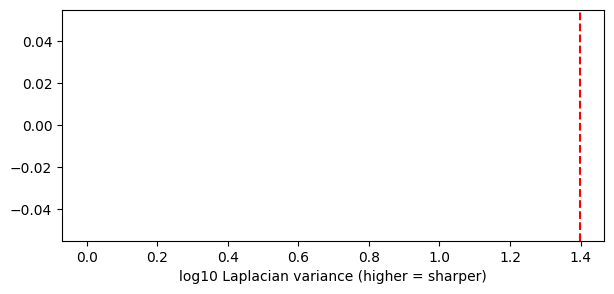

Series([], dtype: int64)

kept per source:
Series([], dtype: int64)


In [21]:
# Look at the blur distribution, then tune BLUR_MIN / MIN_SIDE / BLANK_STD_MIN above and re-run THIS cell (cheap).
import matplotlib.pyplot as plt
ok_stats = man.dropna(subset=['blur'])
plt.figure(figsize=(7, 3)); plt.hist(np.log10(ok_stats.blur.clip(lower=0.1)), bins=60)
plt.axvline(np.log10(BLUR_MIN), c='r', ls='--'); plt.xlabel('log10 Laplacian variance (higher = sharper)'); plt.show()

# reset status, then apply the rules in order
corrupt = man.reason == 'corrupt'; unreadable = man.reason.isin(['unreadable_video', 'no_frames'])
man['status'] = np.where(corrupt | unreadable, 'rejected', 'ok'); man['reason'] = np.where(corrupt | unreadable, man.reason, '')

def reject(mask, reason):
    m = mask & (man.status == 'ok'); man.loc[m, 'status'] = 'rejected'; man.loc[m, 'reason'] = reason

reject(np.minimum(man.width, man.height) < MIN_SIDE, 'too_small')
reject(man.contrast < BLANK_STD_MIN, 'blank')
reject((man.blur < BLUR_MIN) & ~man.has_label, 'blurry')

# exact duplicates (same bytes); prefer to keep the human-labelled copy
cand = man[man.status == 'ok'].sort_values('has_label', ascending=False, kind='stable')
reject(man.index.isin(cand[cand.duplicated('md5', keep='first')].index), 'exact_duplicate')

# near duplicates in video: compare with the last kept frame of the same video
if NEAR_DUP_VIDEO:
    vf = man[(man.status == 'ok') & (man.kind == 'video_frame')].sort_values('t_sec')
    for vid, g in vf.groupby('video'):
        last = None
        for i in g.index:
            t = thumbs[i].astype(np.int16)
            if last is not None:
                d = np.abs(t - last)
                if d.mean() < NEAR_DUP_MAD and d.reshape(12, 8, 12, 8).mean((1, 3)).max() < NEAR_DUP_BLOCK:
                    man.at[i, 'status'], man.at[i, 'reason'] = 'rejected', 'near_duplicate'; continue
            last = t

# near duplicates among still images: perceptual hash, compared against everything kept so far
POP = np.array([bin(v).count('1') for v in range(256)], dtype=np.uint8)
st = man[(man.status == 'ok') & (man.kind == 'image')].sort_values('has_label', ascending=False, kind='stable')
buf, k = np.zeros(len(st), np.uint64), 0
for i in st.index:
    h = hashes[i]
    if k and not man.at[i, 'has_label']:
        dist = POP[(buf[:k] ^ h).view(np.uint8)].reshape(-1, 8).sum(1)
        if dist.min() <= IMG_HASH_DIST:
            man.at[i, 'status'], man.at[i, 'reason'] = 'rejected', 'near_duplicate'; continue
    buf[k] = h; k += 1

print(man.groupby(['kind', 'status', 'reason']).size())
print("\nkept per source:"); print(man[man.status == 'ok'].groupby('source').size())
man.to_csv(ROOT / 'manifest.csv', index=False)

## B2. Labelling: auto pre-labels, human review, label validation

Labelling cannot be fully automated, and you shouldn't try. A model that labels data for the model you are training bakes its own mistakes into the ground truth, and your test metrics then only measure agreement with that model. The pipeline below automates the boring 80% and puts humans where they matter:

1. **Pre-label** every unlabelled frame with a detector (zero-shot YOLO-World by default, or your own earlier model).
2. **Triage** by confidence: `review_uncertain` first, then `review_high` (quick confirm), plus a random audit of `no_det` frames.
3. **Weapon-free footage** (`neg_*` folders) needs no labelling: every frame is a negative. Any detection there is a guaranteed false positive, which makes it a **hard negative** to train on.
4. You fix boxes in a labelling tool (Roboflow, CVAT, Label Studio) and drop the exported YOLO labels back into Drive.
5. **Validate** every label file (bad class ids, out-of-range or zero-area boxes, duplicate boxes) and write the final dataset.

Unreviewed labels on footage that may contain weapons are **not** used by default, and any source that contains auto-only labels is kept out of val/test.

In [ ]:
PRELABEL_WEIGHTS = None     # e.g. RUNS/'v1'/'weights'/'best.pt' (your own model; class order must match CLASSES). None = zero-shot YOLO-World
WORLD_PROMPTS = list(CLASSES)   # zero-shot text prompts, same order as CLASSES
PRE_CONF, HIGH_CONF = 0.10, 0.50                # below PRE_CONF: ignored | >= HIGH_CONF: "likely" tier
AUDIT_FRAC = 0.05                               # share of no-detection frames sent to humans to catch missed weapons

from ultralytics import YOLO, YOLOWorld
if PRELABEL_WEIGHTS:
    pm = YOLO(str(PRELABEL_WEIGHTS)); assert len(pm.names) == len(CLASSES), 'class mismatch'
else:
    pm = YOLOWorld('yolov8l-worldv2.pt'); pm.set_classes(WORLD_PROMPTS)

man['n_det'] = 0; man['max_conf'] = 0.0
todo = man[(man.status == 'ok') & (~man.has_label)]
for i, r in tqdm(zip(todo.index, pm.predict(source=todo.path.tolist(), imgsz=960, conf=PRE_CONF, iou=0.6, stream=True, verbose=False)), total=len(todo), desc='pre-label'):
    b = r.boxes; lines = []
    for (x, y, w, h), c, cl in zip(b.xywhn.cpu().numpy(), b.conf.cpu().numpy(), b.cls.cpu().numpy()):
        lines.append(f'{int(cl)} {x:.6f} {y:.6f} {w:.6f} {h:.6f}')
    (WORK / 'auto_labels' / f"{Path(man.at[i, 'fname']).stem}.txt").write_text('\n'.join(lines) + ('\n' if lines else ''))
    man.at[i, 'n_det'] = len(lines); man.at[i, 'max_conf'] = float(b.conf.max()) if len(lines) else 0.0

def tier(r):
    if r.has_label: return 'human'
    if r.neg: return 'hard_negative' if r.n_det > 0 else 'negative'
    if r.n_det == 0: return 'no_det'
    return 'review_high' if r.max_conf >= HIGH_CONF else 'review_uncertain'

man['tier'] = ''
okm = man.status == 'ok'
man.loc[okm, 'tier'] = man[okm].apply(tier, axis=1)
print(man[okm].groupby('tier').size())
man.to_csv(ROOT / 'manifest.csv', index=False)

In [ ]:
# Build the review package: one folder per priority tier, ready to upload to Roboflow / CVAT / Label Studio.
REVIEW = ROOT / 'review'
rng = np.random.default_rng(0)
nodet = man[man.tier == 'no_det'].index.to_numpy()
audit = set(rng.choice(nodet, size=int(len(nodet) * AUDIT_FRAC), replace=False).tolist()) if len(nodet) else set()

counts = collections.Counter()
for i, r in man[okm].iterrows():
    t = 'no_det_audit' if i in audit else r.tier
    if t not in ('review_uncertain', 'review_high', 'no_det_audit'): continue
    for sub in ('images', 'labels'): (REVIEW / t / sub).mkdir(parents=True, exist_ok=True)
    shutil.copy(r.path, REVIEW / t / 'images' / r.fname)
    stem = Path(r.fname).stem
    lp = WORK / 'auto_labels' / f'{stem}.txt'
    shutil.copy(lp, REVIEW / t / 'labels' / f'{stem}.txt') if lp.exists() else (REVIEW / t / 'labels' / f'{stem}.txt').write_text('')
    counts[t] += 1

for t in counts:
    (REVIEW / t / 'data.yaml').write_text('train: images\nval: images\nnames:\n' + ''.join(f'  {j}: {c}\n' for j, c in enumerate(CLASSES)))
    shutil.make_archive(str(REVIEW / t), 'zip', REVIEW / t)
print(dict(counts)); print('Review packages (zip) are in', REVIEW)
print('\nNEXT: review in this order -> review_uncertain, review_high, no_det_audit.')
print('Export corrected labels as YOLO .txt files into', ROOT / 'review_done' / 'labels', '(flat folder), then run the next cell.')

In [ ]:
REVIEW_DONE = ROOT / 'review_done' / 'labels'   # human-corrected YOLO .txt files exported from your labelling tool
AUTO_ACCEPT_HIGH = False                        # True = also use UNREVIEWED high-confidence auto labels (train only; not recommended)

def clean_label(lines, nc, issues):
    out = []
    for ln in lines:
        p = ln.split()
        if not p: continue
        try:
            c = int(float(p[0])); x, y, w, h = map(float, p[1:5])
        except Exception:
            issues['malformed_line'] += 1; continue
        if not (0 <= c < nc): issues['bad_class_id'] += 1; continue
        x1, y1, x2, y2 = x - w/2, y - h/2, x + w/2, y + h/2
        if x1 < 0 or y1 < 0 or x2 > 1 or y2 > 1: issues['clipped_to_image'] += 1
        x1, y1, x2, y2 = max(0, x1), max(0, y1), min(1, x2), min(1, y2)
        if x2 - x1 < 0.002 or y2 - y1 < 0.002: issues['zero_or_tiny_box'] += 1; continue
        box = (c, x1, y1, x2, y2)
        def iou(a, b):
            iw, ih = min(a[3], b[3]) - max(a[1], b[1]), min(a[4], b[4]) - max(a[2], b[2])
            if iw <= 0 or ih <= 0: return 0.0
            inter = iw * ih
            return inter / ((a[3]-a[1])*(a[4]-a[2]) + (b[3]-b[1])*(b[4]-b[2]) - inter)
        if any(b[0] == c and iou(b, box) > 0.9 for b in out): issues['duplicate_box'] += 1; continue
        out.append(box)
    return [f'{c} {(a+c2)/2:.6f} {(b+d)/2:.6f} {c2-a:.6f} {d-b:.6f}' for c, a, b, c2, d in out]

for sub in ('images', 'labels'): (RAW / sub).mkdir(parents=True, exist_ok=True)
issues = collections.Counter(); man['label_source'] = ''
for i, r in tqdm(man[okm].iterrows(), total=okm.sum(), desc='finalise'):
    stem = Path(r.fname).stem
    if r.has_label:                              src_lines, how = Path(r.label_path).read_text().splitlines(), 'human'
    elif (REVIEW_DONE / f'{stem}.txt').exists(): src_lines, how = (REVIEW_DONE / f'{stem}.txt').read_text().splitlines(), 'reviewed'
    elif r.neg:                                  src_lines, how = [], 'negative'
    elif AUTO_ACCEPT_HIGH and r.tier == 'review_high':
        src_lines, how = (WORK / 'auto_labels' / f'{stem}.txt').read_text().splitlines(), 'auto'
    else:
        man.at[i, 'label_source'] = 'unlabeled'; continue
    lines = clean_label(src_lines, len(CLASSES), issues)
    shutil.copy(r.path, RAW / 'images' / r.fname)
    (RAW / 'labels' / f'{stem}.txt').write_text('\n'.join(lines) + ('\n' if lines else ''))
    man.at[i, 'label_source'] = how

print(man[okm].groupby('label_source').size())
print('\nlabel issues fixed/dropped:', dict(issues))
n_un = int((man.label_source == 'unlabeled').sum())
if n_un: print(f'\n{n_un} frames are still unlabeled and are EXCLUDED (review more of the queue, or they stay out of training).')
man.to_csv(ROOT / 'manifest.csv', index=False)
man[man.label_source.isin(['human', 'reviewed', 'negative', 'auto'])][['fname', 'source', 'label_source']].to_csv(RAW / 'provenance.csv', index=False)

## B3. Leak-free split
Splits `dataset_raw` **by source** (the subfolder name) into train / val / test inside `dataset_sa/`. Sources with auto-only labels are forced into train, so **val and test stay human-verified**. You need several sources (ideally 10 or more).

In [ ]:
import random
RAW = ROOT / 'dataset_raw'
DATA_SA = ROOT / 'dataset_sa'
RUN_SPLIT = True
OVERWRITE_SPLIT = False   # True = write into an existing, non-empty DATA folder anyway

if RUN_SPLIT:
    if (DATA_SA/'images').exists() and any((DATA_SA/'images').rglob('*')) and not OVERWRITE_SPLIT:
        raise RuntimeError(f'{DATA_SA}/images is not empty. Set OVERWRITE_SPLIT = True to add to it, or point DATA elsewhere.')
    random.seed(0)
    imgs = [p for p in (RAW/'images').rglob('*') if p.suffix.lower() in IMG_EXT]
    groups = {}
    for p in imgs:
        groups.setdefault(p.name.split('__')[0], []).append(p)

    prov = pd.read_csv(RAW/'provenance.csv') if (RAW/'provenance.csv').exists() else None
    auto_keys = set(prov.loc[prov.label_source == 'auto', 'source']) if prov is not None else set()
    keys = sorted(k for k in groups if k not in auto_keys); random.shuffle(keys)
    if len(keys) < 6: print(f'WARNING: only {len(keys)} human-verified sources; val/test will be tiny or empty. Collect from more cameras/sites.')
    n = len(keys); cut1, cut2 = int(n*0.70), int(n*0.85)
    assign = {k: ('train' if i < cut1 else 'val' if i < cut2 else 'test') for i, k in enumerate(keys)}
    assign.update({k: 'train' for k in auto_keys if k in groups})

    for k, plist in groups.items():
        s = assign[k]
        for p in plist:
            (DATA_SA/'images'/s).mkdir(parents=True, exist_ok=True)
            (DATA_SA/'labels'/s).mkdir(parents=True, exist_ok=True)
            shutil.copy(p, DATA_SA/'images'/s/p.name)
            lp = RAW/'labels'/(p.stem + '.txt')
            if lp.exists(): shutil.copy(lp, DATA_SA/'labels'/s/lp.name)
    print({s: sum(len(g) for k, g in groups.items() if assign[k] == s) for s in ['train', 'val', 'test']})
print('Now set DATA = DATA_SA, RUN_NAME = "v2", MODEL = RUNS/"v1"/"weights"/"best.pt" and re-run sections 3 to 9.')

# Part C (optional): test the hosted Roboflow model on your own images and video

This sends frames to Roboflow's servers, where your `handgun-detection` workflow runs. It is a quick way to see how an off-the-shelf model behaves on your clips. It does **not** train your own model.
Only upload footage you have permission to send to a third party (POPIA). The video code sends one request per sampled frame, so keep `VIDEO_FPS` low.

Install in its own cell, then restart the session if Colab asks (and re-run the Config cell afterwards).

In [ ]:
!pip -q install inference-sdk

In [ ]:
import cv2, numpy as np
from pathlib import Path
from tqdm.auto import tqdm
from google.colab import userdata
from inference_sdk import InferenceHTTPClient, InferenceConfiguration

WS, WF     = "hamuri", "handgun-detection-kvaef-7iqak"
CLASS_MAP  = {"handgun": 0}
CONF_MIN   = 0.25
VIDEO_FPS  = 1.0
OUT        = Path("/content/rf_out"); [(OUT/d).mkdir(parents=True, exist_ok=True) for d in ("images", "labels", "annotated")]

# >>> SET THESE to files that really exist (Colab sidebar > Files > right-click > Copy path) <<<
TEST_IMAGES_DIR = "/content/drive/MyDrive/weapon_det/test_images"
TEST_VIDEO      = "/content/drive/MyDrive/weapon_det/test_video.mp4"

client = InferenceHTTPClient(api_url="https://serverless.roboflow.com", api_key=userdata.get("ROBOFLOW_KEY")
        ).configure(InferenceConfiguration(api_key_transport="header"))

def detect(img):
    res = client.run_workflow(workspace_name=WS, workflow_id=WF, images={"image": img}, use_cache=True)
    out = res[0] if isinstance(res, list) else res
    p = out.get("predictions", [])
    return p.get("predictions", []) if isinstance(p, dict) else p

def to_yolo(preds, w, h):
    lines = []
    for d in preds:
        c = CLASS_MAP.get(str(d.get("class", "")).lower())
        if c is None or d.get("confidence", 0) < CONF_MIN: continue
        lines.append(f"{c} {d['x']/w:.6f} {d['y']/h:.6f} {d['width']/w:.6f} {d['height']/h:.6f}")
    return lines

def save(frame, stem, preds):
    h, w = frame.shape[:2]; lines = to_yolo(preds, w, h)
    cv2.imwrite(str(OUT/"images"/f"{stem}.jpg"), frame)
    (OUT/"labels"/f"{stem}.txt").write_text("\n".join(lines) + ("\n" if lines else ""))
    ann = frame.copy()
    for d in preds:
        if d.get("confidence", 0) < CONF_MIN: continue
        x1, y1 = int(d["x"]-d["width"]/2), int(d["y"]-d["height"]/2)
        cv2.rectangle(ann, (x1, y1), (int(d["x"]+d["width"]/2), int(d["y"]+d["height"]/2)), (0, 0, 255), 2)
        cv2.putText(ann, f"{d.get('class','')} {d['confidence']:.2f}", (x1, max(12, y1-4)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)
    cv2.imwrite(str(OUT/"annotated"/f"{stem}.jpg"), ann)
    return len(lines)

def run_images(folder):
    folder = Path(folder)
    if not folder.is_dir(): raise FileNotFoundError(f"Image folder not found: {folder}")
    files = [p for p in sorted(folder.glob("*")) if p.suffix.lower() in IMG_EXT]
    if not files: raise FileNotFoundError(f"No images in {folder}")
    for p in tqdm(files):
        frame = cv2.imread(str(p))
        if frame is None: print("unreadable:", p.name); continue
        print(f"{p.name}: {save(frame, p.stem, detect(frame))} detection(s)")

def run_video(path):
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened(): raise FileNotFoundError(f"Cannot open video: {path}")
    fps = cap.get(cv2.CAP_PROP_FPS) or 25
    step, i, hits = max(1, round(fps / VIDEO_FPS)), 0, []
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT) / step) + 1
    with tqdm(total=total) as bar:
        while cap.grab():
            if i % step == 0:
                ok, frame = cap.retrieve()
                if ok:
                    preds = detect(frame); t = i / fps
                    if any(d.get("confidence", 0) >= CONF_MIN for d in preds):
                        save(frame, f"{Path(path).stem}_{t:07.2f}s", preds); hits.append(round(t, 1))
                    bar.update(1)
            i += 1
    cap.release()
    print(f"{Path(path).name}: detections at (seconds): {hits}")

In [ ]:
# Run whichever you have. Outputs go to /content/rf_out (annotated/ shows boxes, labels/ has YOLO pre-labels to REVIEW before use).
run_images(TEST_IMAGES_DIR)
run_video(TEST_VIDEO)